# Phase 1 — Collecte et nettoyage des données

Analyse des cours de clôture du S&P 500, du CAC 40 et du FTSE 100. Le script de préparation conserve les téléchargements bruts et produit les tables nettoyées examinées dans ce notebook.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'data/processed/sp500_prices.csv').exists(), 'Open this notebook from the workspace or notebooks folder.'

## 1. Chargement des données du S&P 500

Le fichier est chargé avec `read_csv`. Le paramètre `parse_dates` convertit la colonne de dates pour les traitements temporels.

In [2]:
prices = pd.read_csv(ROOT / 'data/processed/sp500_prices.csv', parse_dates=['date'])
prices.head()

,date,close
0,2016-09-06,2186.479980
1,2016-09-07,2186.159912
2,2016-09-08,2181.300049
3,2016-09-09,2127.810059
4,2016-09-12,2159.040039


## 2. Structure du jeu de données

Inspection des types de colonnes et du nombre d’observations.

In [3]:
prices.info()
print('Rows:', len(prices))
print('First date:', prices['date'].min())
print('Last date:', prices['date'].max())

<class 'pandas.DataFrame'>
RangeIndex: 2514 entries, 0 to 2513
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    2514 non-null   datetime64[us]
 1   close   2514 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 39.4 KB
Rows: 2514
First date: 2016-09-06 00:00:00
Last date: 2026-09-04 00:00:00


## 3. Contrôles des données préparées

Recherche de valeurs manquantes, de dates dupliquées et de prix invalides dans la table nettoyée. Les lignes rejetées lors de la préparation sont enregistrées séparément.

In [4]:
print('Missing values:')
print(prices.isna().sum())
print('Duplicate dates:', prices['date'].duplicated().sum())
print('Non-positive prices:', (prices['close'] <= 0).sum())
print('Dates sorted:', prices['date'].is_monotonic_increasing)

Missing values:
date     0
close    0
dtype: int64
Duplicate dates: 0
Non-positive prices: 0
Dates sorted: True


## 4. Historique des cours de clôture

L’axe vertical représente le niveau de l’indice en points.

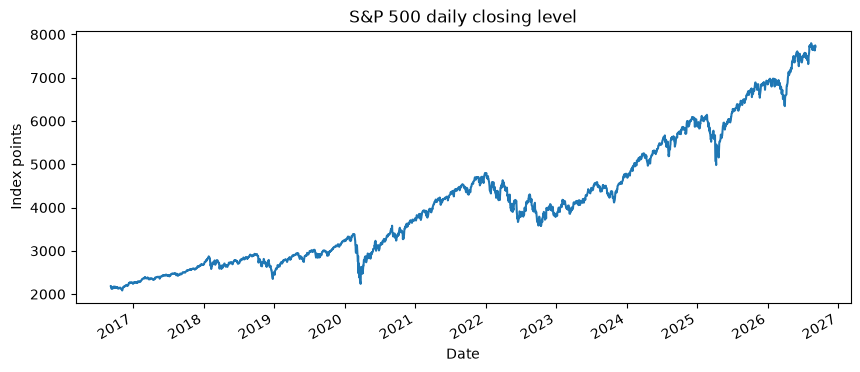

In [5]:
ax = prices.plot(x='date', y='close', figsize=(10, 4), title='S&P 500 daily closing level', legend=False)
ax.set_ylabel('Index points')
ax.set_xlabel('Date')
plt.show()

## 5. Synthèse du nettoyage

Comparaison du nombre de lignes et de la couverture des trois séries.

In [6]:
pd.read_csv(ROOT / 'reports/phase1_quality_summary.csv')

,index,raw_rows,clean_rows,start,end,rejected_rows,exact_duplicates_removed,moves_over_10_percent_for_review,absent_weekdays_including_holidays
0,S&P 500,2514,2514,2016-09-06,2026-09-04,0,0,1,95
1,CAC 40,2560,2559,2016-09-06,2026-09-04,1,0,1,50
2,FTSE 100,2526,2525,2016-09-06,2026-09-04,1,0,1,84


## 6. Inspection des variations inhabituelles

Les grandes variations sont signalées pour contrôle puis conservées lorsqu’elles correspondent à des observations valides. Les valeurs sont exprimées en unités décimales : 0,10 correspond à 10 %. Les jours de semaine absents sont rapprochés du calendrier de marché.

In [7]:
pd.read_csv(ROOT / 'data/processed/sp500_review_flags.csv')

,date,close,daily_change_fraction
0,2020-03-16,2386.129883,-0.119841


In [8]:
pd.read_csv(ROOT / 'data/processed/sp500_absent_weekdays.csv').head(10)

,date
0,2016-11-24
1,2016-12-26
2,2017-01-02
3,2017-01-16
4,2017-02-20
5,2017-04-14
6,2017-05-29
7,2017-07-04
8,2017-09-04
9,2017-11-23


## 7. Contrôles du CAC 40

Inspection des premières observations, des valeurs manquantes et de l’historique des prix.

In [9]:
cac40 = pd.read_csv(ROOT / 'data/processed/cac40_prices.csv', parse_dates=['date'])
cac40.head()

,date,close
0,2016-09-06,4529.959961
1,2016-09-07,4557.660156
2,2016-09-08,4542.200195
3,2016-09-09,4491.399902
4,2016-09-12,4439.799805


date     0
close    0
dtype: int64


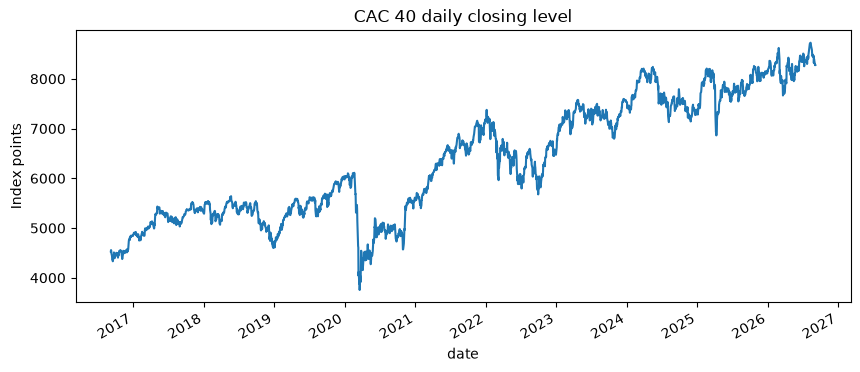

In [10]:
print(cac40.isna().sum())
ax = cac40.plot(x='date', y='close', figsize=(10, 4), title='CAC 40 daily closing level', legend=False)
ax.set_ylabel('Index points')
plt.show()

## 8. Contrôles du FTSE 100

Les mêmes contrôles sont appliqués au marché britannique, en conservant son calendrier de séances.

In [11]:
ftse100 = pd.read_csv(ROOT / 'data/processed/ftse100_prices.csv', parse_dates=['date'])
print('Rows:', len(ftse100))
print(ftse100.isna().sum())
print('Duplicate dates:', ftse100['date'].duplicated().sum())
ftse100.head()

Rows: 2525
date     0
close    0
dtype: int64
Duplicate dates: 0


,date,close
0,2016-09-06,6826.100098
1,2016-09-07,6846.600098
2,2016-09-08,6858.700195
3,2016-09-09,6777.000000
4,2016-09-12,6700.899902


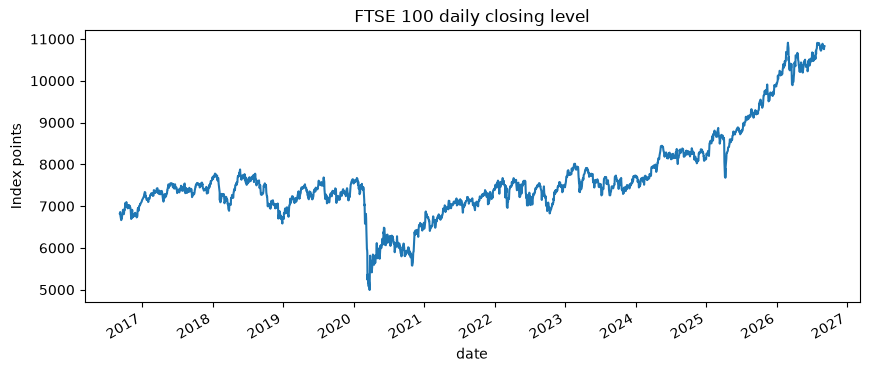

In [12]:
ax = ftse100.plot(x='date', y='close', figsize=(10, 4), title='FTSE 100 daily closing level', legend=False)
ax.set_ylabel('Index points')
plt.show()

## 9. Provenance et lacune du FTSE 100

Les prix proviennent de Yahoo Finance. La clôture du 22 décembre 2020 reste manquante après une requête ciblée. Aucune interpolation ni substitution de prix n’est appliquée.

In [13]:
pd.read_csv(ROOT / 'reports/ftse100_missing_sessions.csv')

,date
0,2020-12-22


## 10. Vérification des calendriers

Les dates observées sont comparées aux calendriers de New York, Paris et Londres. Ces contrôles évaluent la couverture des séances ; l’exactitude de chaque prix constitue une question distincte.

In [14]:
pd.read_csv(ROOT / 'reports/calendar_checks.csv')

,index_key,calendar,expected_sessions,observations,missing_sessions,unexpected_dates
0,sp500,XNYS,2514,2514,0,0
1,cac40,XPAR,2559,2559,0,0
2,ftse100,XLON,2526,2525,1,0


## Synthèse

- Un enregistrement vide du CAC 40 correspondant à un jour férié a été exclu.
- Une clôture du FTSE 100 manque le 22 décembre 2020.
- Les mouvements extrêmes examinés sont conservés.
- Les rendements quotidiens FTSE des 22 et 23 décembre 2020 sont indisponibles. Les indicateurs d’intervalle permettent d’exclure les variations traversant la lacune des calculs quotidiens.